In [1]:
%matplotlib inline
import scrublet as scr
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import scanpy as sc

In [2]:
# WT_IEC

In [2]:
# 1. Load counts matrix and gene list
counts_matrix = scipy.io.mmread("D:/HYJ/scRNA-seq/WT_IEC/filtered_feature_bc_matrix_SoupX_out/matrix.mtx").T.tocsc()
genes = np.array(scr.load_genes("D:/HYJ/scRNA-seq/WT_IEC/filtered_feature_bc_matrix_SoupX_out/genes.tsv", delimiter='\t', column=1))
print('Counts matrix shape: {} rows, {} columns'.format(counts_matrix.shape[0], counts_matrix.shape[1]))
print('Number of genes in gene list: {}'.format(len(genes)))

Counts matrix shape: 13310 rows, 32285 columns
Number of genes in gene list: 32285


In [3]:
# 2. Initialize Scrublet object
scrub = scr.Scrublet(counts_matrix=counts_matrix, sim_doublet_ratio=2.0, n_neighbors=None, expected_doublet_rate=0.06)
# sim_doublet_ratio: the number of doublets to simulate, relative to the number of observed transcriptomes. This should be high enough that all doublet states are well-represented by simulated doublets. Setting it too high is computationally expensive. The default value is 2, though values as low as 0.5 give very similar results for the datasets that have been tested.
# n_neighbors: Number of neighbors used to construct the KNN classifier of observed transcriptomes and simulated doublets. The default value None will use round(0.5*sqrt(n_cells)) and works well.
# expected_doublet_rate: the expected fraction of transcriptomes that are doublets, typically 0.05-0.1. Results are not particularly sensitive to this parameter.

In [4]:
# 3. Run the default pipeline, which includes: Doublet simulation, Normalization, gene filtering, rescaling, PCA, Doublet score calculation, Doublet score threshold detection and doublet calling
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, min_cells=3, min_gene_variability_pctl=85, n_prin_comps=30)
# scrub_doublets() automatically identify the threshold of doublet score

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.50
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 0.0%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 0.0%
Elapsed time: 14.4 seconds


(<Figure size 576x216 with 2 Axes>,
 array([<AxesSubplot:title={'center':'Observed transcriptomes'}, xlabel='Doublet score', ylabel='Prob. density'>,
        <AxesSubplot:title={'center':'Simulated doublets'}, xlabel='Doublet score', ylabel='Prob. density'>],
       dtype=object))

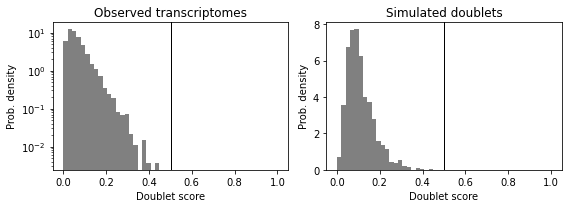

In [5]:
# 4. Plot doublet score histograms
# The simulated doublet histogram is typically bimodal.
# The left mode corresponds to "embedded" doublets generated by two cells with similar gene expression.
# The right mode corresponds to "neotypic" doublets, which are generated by cells with distinct gene expression (e.g., different cell types) and are expected to introduce more artifacts in downstream analyses.
# Scrublet can only detect neotypic doublets.
scrub.plot_histogram()

In [6]:
# 5. Get 2-D embedding to visualize the results
scrub.set_embedding('UMAP', scr.get_umap(X=scrub.manifold_obs_, n_neighbors=10, min_dist=0.3))

(<Figure size 576x288 with 3 Axes>,
 array([<AxesSubplot:title={'center':'Predicted doublets'}, xlabel='UMAP 1', ylabel='UMAP 2'>,
        <AxesSubplot:title={'center':'Doublet score'}, xlabel='UMAP 1', ylabel='UMAP 2'>],
       dtype=object))

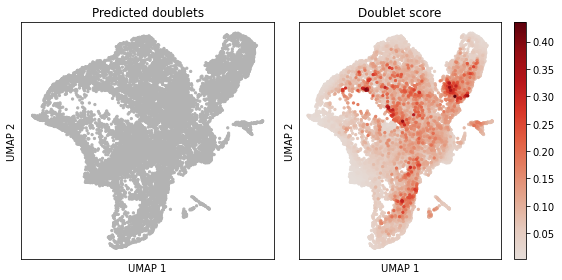

In [8]:
# 6. Plot doublet predictions on 2-D embedding
scrub.plot_embedding('UMAP', order_points=True)

In [9]:
# 7. Export Scrublet results
barcodes = pd.read_csv('C:/Users/Park_Lab/Documents/WT_IEC/filtered_feature_bc_matrix_SoupX_out/barcodes.tsv', delimiter='\t', header=None)
result = pd.DataFrame([barcodes.iloc[:,0], doublet_scores, predicted_doublets], index=["barcode", "doublet_scores","predicted_doublets"]).T
result.to_csv("C:/Users/Park_Lab/Documents/WT_IEC/Scrublet_results.csv")

In [10]:
# save as h5ad after Scrublet

In [11]:
adata = sc.read_10x_mtx(path='C:/Users/Park_Lab/Documents/WT_IEC/filtered_feature_bc_matrix_SoupX_out/', var_names='gene_symbols', cache=True)

In [12]:
adata.var_names_make_unique()
adata

AnnData object with n_obs × n_vars = 13310 × 32285
    var: 'gene_ids'

In [13]:
Cells=pd.read_csv('C:/Users/Park_Lab/Documents/WT_IEC/Scrublet_results.csv', index_col='barcode')
Cells

,Unnamed: 0,doublet_scores,predicted_doublets
barcode,,,
AAACCCAAGAGGCTGT-1,0,0.058116,False
AAACCCAAGCCATGCC-1,1,0.014675,False
AAACCCAAGTCGAAGC-1,2,0.035294,False
AAACCCAAGTGCTCAT-1,3,0.089845,False
AAACCCACAACAGATA-1,4,0.175124,False
...,...,...,...
TTTGTTGGTAGTTACC-1,13305,0.059522,False
TTTGTTGGTATAATGG-1,13306,0.025334,False
TTTGTTGGTCGACGCT-1,13307,0.004775,False


In [14]:
adata.obs['predicted_doublets']=Cells['predicted_doublets']

In [15]:
WI=adata[adata.obs['predicted_doublets']==False]    # slice adata based on bool
WI

View of AnnData object with n_obs × n_vars = 13310 × 32285
    obs: 'predicted_doublets'
    var: 'gene_ids'

In [16]:
WI.write('C:/Users/Park_Lab/Documents/WT_IEC/WI_raw_after_SoupX_Scrublet.h5ad', compression='gzip')

In [17]:
# KO_IEC

In [10]:
# 1. Load counts matrix and gene list
counts_matrix = scipy.io.mmread("D:/HYJ/scRNA-seq/KO_IEC/filtered_feature_bc_matrix_SoupX_out/matrix.mtx").T.tocsc()
genes = np.array(scr.load_genes("D:/HYJ/scRNA-seq/KO_IEC/filtered_feature_bc_matrix_SoupX_out/genes.tsv", delimiter='\t', column=1))
print('Counts matrix shape: {} rows, {} columns'.format(counts_matrix.shape[0], counts_matrix.shape[1]))
print('Number of genes in gene list: {}'.format(len(genes)))

Counts matrix shape: 19508 rows, 32285 columns
Number of genes in gene list: 32285


In [11]:
# 2. Initialize Scrublet object
scrub = scr.Scrublet(counts_matrix=counts_matrix, sim_doublet_ratio=2.0, n_neighbors=None, expected_doublet_rate=0.06)
# sim_doublet_ratio: the number of doublets to simulate, relative to the number of observed transcriptomes. This should be high enough that all doublet states are well-represented by simulated doublets. Setting it too high is computationally expensive. The default value is 2, though values as low as 0.5 give very similar results for the datasets that have been tested.
# n_neighbors: Number of neighbors used to construct the KNN classifier of observed transcriptomes and simulated doublets. The default value None will use round(0.5*sqrt(n_cells)) and works well.
# expected_doublet_rate: the expected fraction of transcriptomes that are doublets, typically 0.05-0.1. Results are not particularly sensitive to this parameter.

In [12]:
# 3. Run the default pipeline, which includes: Doublet simulation, Normalization, gene filtering, rescaling, PCA, Doublet score calculation, Doublet score threshold detection and doublet calling
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, min_cells=3, min_gene_variability_pctl=85, n_prin_comps=30)
# scrub_doublets() automatically identify the threshold of doublet score

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.67
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 0.0%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 26.7%
Elapsed time: 23.9 seconds


(<Figure size 576x216 with 2 Axes>,
 array([<AxesSubplot:title={'center':'Observed transcriptomes'}, xlabel='Doublet score', ylabel='Prob. density'>,
        <AxesSubplot:title={'center':'Simulated doublets'}, xlabel='Doublet score', ylabel='Prob. density'>],
       dtype=object))

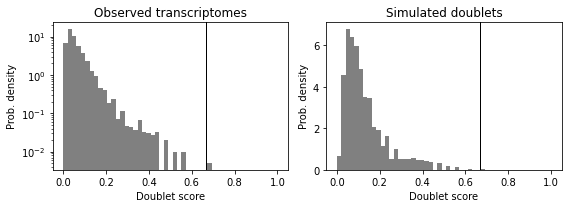

In [13]:
# 4. Plot doublet score histograms
# The simulated doublet histogram is typically bimodal.
# The left mode corresponds to "embedded" doublets generated by two cells with similar gene expression.
# The right mode corresponds to "neotypic" doublets, which are generated by cells with distinct gene expression (e.g., different cell types) and are expected to introduce more artifacts in downstream analyses.
# Scrublet can only detect neotypic doublets.
scrub.plot_histogram()

In [14]:
# 5. Get 2-D embedding to visualize the results
scrub.set_embedding('UMAP', scr.get_umap(X=scrub.manifold_obs_, n_neighbors=10, min_dist=0.3))

(<Figure size 576x288 with 3 Axes>,
 array([<AxesSubplot:title={'center':'Predicted doublets'}, xlabel='UMAP 1', ylabel='UMAP 2'>,
        <AxesSubplot:title={'center':'Doublet score'}, xlabel='UMAP 1', ylabel='UMAP 2'>],
       dtype=object))

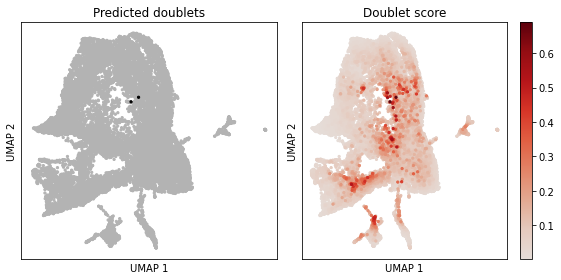

In [15]:
# 6. Plot doublet predictions on 2-D embedding
scrub.plot_embedding('UMAP', order_points=True)

In [24]:
# 7. Export Scrublet results
barcodes = pd.read_csv('C:/Users/Park_Lab/Documents/KO_IEC/filtered_feature_bc_matrix_SoupX_out/barcodes.tsv', delimiter='\t', header=None)
result = pd.DataFrame([barcodes.iloc[:,0], doublet_scores, predicted_doublets], index=["barcode", "doublet_scores","predicted_doublets"]).T
result.to_csv("C:/Users/Park_Lab/Documents/KO_IEC/Scrublet_results.csv")

In [25]:
# save as h5ad after Scrublet

In [26]:
adata = sc.read_10x_mtx(path='C:/Users/Park_Lab/Documents/KO_IEC/filtered_feature_bc_matrix_SoupX_out/', var_names='gene_symbols', cache=True)

In [27]:
adata.var_names_make_unique()
adata

AnnData object with n_obs × n_vars = 19508 × 32285
    var: 'gene_ids'

In [28]:
Cells=pd.read_csv('C:/Users/Park_Lab/Documents/KO_IEC/Scrublet_results.csv', index_col='barcode')
Cells

,Unnamed: 0,doublet_scores,predicted_doublets
barcode,,,
AAACCCAAGAAGTATC-1,0,0.055086,False
AAACCCAAGACATCCT-1,1,0.062039,False
AAACCCAAGACGGTTG-1,2,0.065944,False
AAACCCAAGAGCTGCA-1,3,0.029817,False
AAACCCAAGCACTCAT-1,4,0.052990,False
...,...,...,...
TTTGTTGTCAGCGGAA-1,19503,0.103277,False
TTTGTTGTCATGGTAC-1,19504,0.017172,False
TTTGTTGTCGACGCTG-1,19505,0.027706,False


In [29]:
adata.obs['predicted_doublets']=Cells['predicted_doublets']

In [30]:
ACI=adata[adata.obs['predicted_doublets']==False]    # slice adata based on bool
ACI

View of AnnData object with n_obs × n_vars = 19506 × 32285
    obs: 'predicted_doublets'
    var: 'gene_ids'

In [31]:
ACI.write('C:/Users/Park_Lab/Documents/KO_IEC/ACI_raw_after_SoupX_Scrublet.h5ad', compression='gzip')

In [32]:
# Apc_Cracd_KO_Tumor

In [33]:
# 1. Load counts matrix and gene list
counts_matrix = scipy.io.mmread("C:/Users/Park_Lab/Documents/ACT_Tumor/filtered_feature_bc_matrix_SoupX_out/matrix.mtx").T.tocsc()
genes = np.array(scr.load_genes("C:/Users/Park_Lab/Documents/ACT_Tumor/filtered_feature_bc_matrix_SoupX_out/genes.tsv", delimiter='\t', column=1))
print('Counts matrix shape: {} rows, {} columns'.format(counts_matrix.shape[0], counts_matrix.shape[1]))
print('Number of genes in gene list: {}'.format(len(genes)))

Counts matrix shape: 13499 rows, 32285 columns
Number of genes in gene list: 32285


In [34]:
# 2. Initialize Scrublet object
scrub = scr.Scrublet(counts_matrix=counts_matrix, sim_doublet_ratio=2.0, n_neighbors=None, expected_doublet_rate=0.06)
# sim_doublet_ratio: the number of doublets to simulate, relative to the number of observed transcriptomes. This should be high enough that all doublet states are well-represented by simulated doublets. Setting it too high is computationally expensive. The default value is 2, though values as low as 0.5 give very similar results for the datasets that have been tested.
# n_neighbors: Number of neighbors used to construct the KNN classifier of observed transcriptomes and simulated doublets. The default value None will use round(0.5*sqrt(n_cells)) and works well.
# expected_doublet_rate: the expected fraction of transcriptomes that are doublets, typically 0.05-0.1. Results are not particularly sensitive to this parameter.

In [35]:
# 3. Run the default pipeline, which includes: Doublet simulation, Normalization, gene filtering, rescaling, PCA, Doublet score calculation, Doublet score threshold detection and doublet calling
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, min_cells=3, min_gene_variability_pctl=85, n_prin_comps=30)
# scrub_doublets() automatically identify the threshold of doublet score

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.71
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 0.2%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 8.9%
Elapsed time: 14.8 seconds


(<Figure size 576x216 with 2 Axes>,
 array([<AxesSubplot:title={'center':'Observed transcriptomes'}, xlabel='Doublet score', ylabel='Prob. density'>,
        <AxesSubplot:title={'center':'Simulated doublets'}, xlabel='Doublet score', ylabel='Prob. density'>],
       dtype=object))

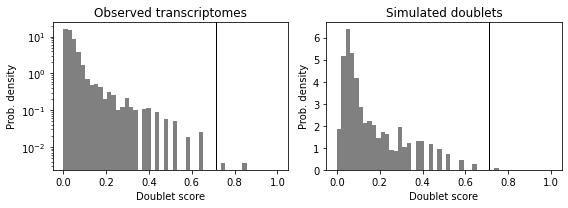

In [36]:
# 4. Plot doublet score histograms
# The simulated doublet histogram is typically bimodal.
# The left mode corresponds to "embedded" doublets generated by two cells with similar gene expression.
# The right mode corresponds to "neotypic" doublets, which are generated by cells with distinct gene expression (e.g., different cell types) and are expected to introduce more artifacts in downstream analyses.
# Scrublet can only detect neotypic doublets.
scrub.plot_histogram()

In [37]:
# 5. Get 2-D embedding to visualize the results
scrub.set_embedding('UMAP', scr.get_umap(X=scrub.manifold_obs_, n_neighbors=10, min_dist=0.3))

(<Figure size 576x288 with 3 Axes>,
 array([<AxesSubplot:title={'center':'Predicted doublets'}, xlabel='UMAP 1', ylabel='UMAP 2'>,
        <AxesSubplot:title={'center':'Doublet score'}, xlabel='UMAP 1', ylabel='UMAP 2'>],
       dtype=object))

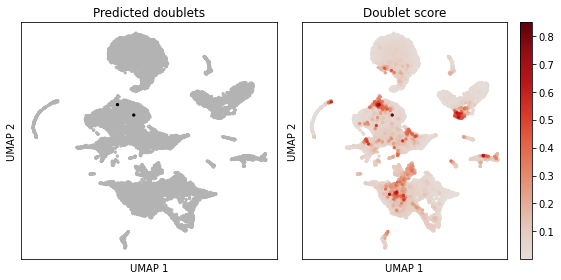

In [38]:
# 6. Plot doublet predictions on 2-D embedding
scrub.plot_embedding('UMAP', order_points=True)

In [39]:
# 7. Export Scrublet results
barcodes = pd.read_csv('C:/Users/Park_Lab/Documents/ACT_Tumor/filtered_feature_bc_matrix_SoupX_out/barcodes.tsv', delimiter='\t', header=None)
result = pd.DataFrame([barcodes.iloc[:,0], doublet_scores, predicted_doublets], index=["barcode", "doublet_scores","predicted_doublets"]).T
result.to_csv("C:/Users/Park_Lab/Documents/ACT_Tumor/Scrublet_results.csv")

In [40]:
# save as h5ad after Scrublet

In [41]:
adata = sc.read_10x_mtx(path='C:/Users/Park_Lab/Documents/ACT_Tumor/filtered_feature_bc_matrix_SoupX_out/', var_names='gene_symbols', cache=True)

In [42]:
adata.var_names_make_unique()
adata

AnnData object with n_obs × n_vars = 13499 × 32285
    var: 'gene_ids'

In [43]:
Cells=pd.read_csv('C:/Users/Park_Lab/Documents/ACT_Tumor/Scrublet_results.csv', index_col='barcode')
Cells

,Unnamed: 0,doublet_scores,predicted_doublets
barcode,,,
AAACCCAAGCAGCAGT-1,0,0.016240,False
AAACCCAAGTAAGACT-1,1,0.050505,False
AAACCCAAGTCGAAGC-1,2,0.087379,False
AAACCCAAGTGCTCGC-1,3,0.013207,False
AAACCCACAAGCGATG-1,4,0.017061,False
...,...,...,...
TTTGTTGGTTGTTGTG-1,13494,0.043090,False
TTTGTTGTCCAGTGCG-1,13495,0.010213,False
TTTGTTGTCCATCCGT-1,13496,0.025907,False


In [44]:
adata.obs['predicted_doublets']=Cells['predicted_doublets']

In [45]:
ACT=adata[adata.obs['predicted_doublets']==False]    # slice adata based on bool
ACT

View of AnnData object with n_obs × n_vars = 13497 × 32285
    obs: 'predicted_doublets'
    var: 'gene_ids'

In [46]:
ACT.write('C:/Users/Park_Lab/Documents/ACT_Tumor/ACT_raw_after_SoupX_Scrublet.h5ad', compression='gzip')